# 01 — Data exploration

## Purpose

We study **short-term solar photovoltaic (PV) power forecasting** and, later, whether features derived from the Vedic calendar (Panchang) improve forecasts.

Before building any models, we examine the SOLETE dataset to answer three questions:

1. Are the measurements and timestamps suitable for time-series forecasting?
2. Which data-quality issues need attention during preparation?
3. Which sampling resolution should we use for forecasts 15, 30, and 60 minutes ahead?

This notebook **only reads and describes data**.

**Data:** SOLETE, collected at the SYSLAB facility in Denmark. Source: Pombo, Gehrke and Bindner (2022), *Data in Brief*, DOI: [10.1016/j.dib.2022.108046](https://doi.org/10.1016/j.dib.2022.108046); dataset DOI: [10.11583/DTU.17040767](https://doi.org/10.11583/DTU.17040767).

## 1. Load the data

SOLETE is available at hourly, 5-minute, 1-minute and 1-second resolution. We load the three smaller files for direct comparison. The 1-second file is much larger, so we read **only its dimensions**, not all of its measurements.

We use the project's existing data loader. The original files are not changed.

In [1]:
from pathlib import Path
import sys

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# This works when VS Code starts the kernel in the project or notebooks folder.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "solete_dataset").is_dir()
     and (p / "src" / "data_loader.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the project folder in VS Code.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_solete

DATA_DIR = PROJECT_ROOT / "solete_dataset"
paths = {name: DATA_DIR / f"SOLETE_Pombo_{name}.h5"
         for name in ("60min", "5min", "1min", "1sec")}

for name in ("60min", "5min", "1min"):
    if not paths[name].is_file():
        raise FileNotFoundError(f"Missing SOLETE file: {paths[name]}")

raw_data = {name: load_solete(paths[name]) for name in ("60min", "5min", "1min")}
data = {name: frame.sort_index() for name, frame in raw_data.items()}

for name, frame in data.items():
    assert isinstance(frame.index, pd.DatetimeIndex)
    assert str(frame.index.tz) == "UTC", f"{name}: timestamps must be UTC"
    assert "P_Solar[kW]" in frame.columns

print("SOLETE data loaded for the 60-minute, 5-minute and 1-minute resolutions.")

SOLETE data loaded for the 60-minute, 5-minute and 1-minute resolutions.


## 2. Check the timestamps

Forecasting models need observations in the correct order. We check for duplicate timestamps and gaps in each regular time grid.

The hourly source file may not be stored in chronological order, so we show its **original order** and then work with a sorted copy. Sorting changes the row order, not the measurements.

In [2]:
frequency = {"60min": "60min", "5min": "5min", "1min": "1min"}
rows = []
for name in ("60min", "5min", "1min"):
    original = raw_data[name]
    frame = data[name]
    expected = pd.date_range(frame.index.min(), frame.index.max(), freq=frequency[name])
    rows.append({
        "resolution": name,
        "rows": len(frame),
        "variables": frame.shape[1],
        "first_time_UTC": frame.index.min(),
        "last_time_UTC": frame.index.max(),
        "source_chronological": original.index.is_monotonic_increasing,
        "duplicate_times": int(frame.index.duplicated().sum()),
        "missing_times": len(expected.difference(frame.index)),
        "missing_measurements": int(frame.isna().sum().sum()),
    })

structure = pd.DataFrame(rows).set_index("resolution")
display(structure)

if paths["1sec"].is_file():
    with h5py.File(paths["1sec"], "r") as h5:
        one_second_rows, one_second_columns = h5["DATA"]["block0_values"].shape
    print(f"1-second file: {one_second_rows:,} rows and {one_second_columns} variables.")
    print("The 1-second timestamps and measurement values are not audited here.")
else:
    print("1-second file not found; it is not needed for this notebook.")

,rows,variables,first_time_UTC,last_time_UTC,source_chronological,duplicate_times,missing_times,missing_measurements
resolution,,,,,,,,
60min,10969,11,2018-06-01 00:00:00+00:00,2019-09-01 00:00:00+00:00,False,0,0,0
5min,131617,11,2018-06-01 00:00:00+00:00,2019-09-01 00:00:00+00:00,True,0,0,0
1min,658081,11,2018-06-01 00:00:00+00:00,2019-09-01 00:00:00+00:00,True,0,0,0


1-second file: 39,484,801 rows and 11 variables.
The 1-second timestamps and measurement values are not audited here.


## 3. Identify the forecasting target

The dataset contains both solar (`P_Solar[kW]`) and wind (`P_Gaia[kW]`) generation. Our research question concerns **solar PV power**, so `P_Solar[kW]` is the target. Wind generation is not another prediction target in this study.

We inspect both measurements to understand their distributions. These statistics are descriptive, not model performance.

In [3]:
target_rows = []
for name, frame in data.items():
    for variable in ("P_Solar[kW]", "P_Gaia[kW]"):
        x = frame[variable]
        target_rows.append({
            "resolution": name,
            "variable": variable,
            "observations": int(x.notna().sum()),
            "mean_kW": x.mean(),
            "max_kW": x.max(),
            "zero_percent": 100 * (x == 0).mean(),
            "missing": int(x.isna().sum()),
        })

target_summary = pd.DataFrame(target_rows)
display(target_summary.round(3))

,resolution,variable,observations,mean_kW,max_kW,zero_percent,missing
0,60min,P_Solar[kW],10969,1.030,6.975,38.326,0
1,60min,P_Gaia[kW],10969,0.016,10.185,99.562,0
2,5min,P_Solar[kW],131617,0.988,7.715,41.258,0
3,5min,P_Gaia[kW],131617,2.695,23.331,29.489,0
4,1min,P_Solar[kW],658081,0.988,8.405,41.400,0
5,1min,P_Gaia[kW],658081,2.692,23.479,34.329,0


## 4. Inspect measurement quality in the 5-minute data

We examine the 5-minute file in more detail because it is the candidate for the main forecasting experiments.

The checks below **flag unusual values**; they do not automatically mark a measurement as wrong or replace it. In particular, the humidity source label contains `%`, but the measured values often behave like fractions. Pressure also contains values that deserve closer inspection.

In [4]:
pv_data = data["5min"]
required = [
    "P_Solar[kW]", "GHI[kW1m2]", "POA Irr[kW1m2]",
    "HUMIDITY[%]", "Pressure[mbar]", "WIND_DIR[deg]",
]
missing_columns = sorted(set(required) - set(pv_data.columns))
if missing_columns:
    raise KeyError(f"Missing source variables: {missing_columns}")

quality = pd.Series({
    "Missing measurements (all variables)": int(pv_data.isna().sum().sum()),
    "Negative solar-power values": int((pv_data["P_Solar[kW]"] < 0).sum()),
    "Negative GHI values": int((pv_data["GHI[kW1m2]"] < 0).sum()),
    "Humidity outside [0, 1]": int(((pv_data["HUMIDITY[%]"] < 0) |
                                      (pv_data["HUMIDITY[%]"] > 1)).sum()),
    "Pressure above 1100 mbar": int((pv_data["Pressure[mbar]"] > 1100).sum()),
    "Wind direction outside [0, 360)": int(((pv_data["WIND_DIR[deg]"] < 0) |
                                               (pv_data["WIND_DIR[deg]"] >= 360)).sum()),
}, name="observations")
display(quality.to_frame())

display(pv_data[required].describe().loc[["min", "25%", "50%", "75%", "max"]].round(3))

,observations
Missing measurements (all variables),0
Negative solar-power values,0
Negative GHI values,0
"Humidity outside [0, 1]",164
Pressure above 1100 mbar,456
"Wind direction outside [0, 360)",103


,P_Solar[kW],GHI[kW1m2],POA Irr[kW1m2],HUMIDITY[%],Pressure[mbar],WIND_DIR[deg]
min,0.000,0.000,0.000,0.0,974.263,0.000
25%,0.000,0.000,0.000,0.7,1000.000,145.797
50%,0.071,0.011,0.009,0.8,1010.903,215.920
75%,1.185,0.208,0.169,0.9,1016.746,276.343
max,7.715,1.092,1.120,2.0,2034.520,680.000


## 5. Check whether unusual pressure values occur at midnight

If suspicious values repeat at the same time each day, that is useful evidence for the next notebook's cleaning decisions. We check the timing of values above 1100 mbar without changing them.

In [5]:
midnight = (pv_data.index.hour == 0) & (pv_data.index.minute == 0)
high_pressure = pv_data["Pressure[mbar]"] > 1100
pressure_report = pd.Series({
    "All observations above 1100 mbar": int(high_pressure.sum()),
    "Above 1100 mbar at midnight UTC": int((high_pressure & midnight).sum()),
    "Above 1100 mbar outside midnight UTC": int((high_pressure & ~midnight).sum()),
}, name="count")
display(pressure_report.to_frame())

# Show a short real sequence surrounding midnight for inspection.
window = pv_data.loc[
    "2018-12-07 23:45:00+00:00":"2018-12-08 00:15:00+00:00",
    ["Pressure[mbar]", "HUMIDITY[%]", "P_Solar[kW]"],
]
display(window)

,count
All observations above 1100 mbar,456
Above 1100 mbar at midnight UTC,456
Above 1100 mbar outside midnight UTC,0


,Pressure[mbar],HUMIDITY[%],P_Solar[kW]
Timestamp,,,
2018-12-07 23:45:00+00:00,1000.0,0.9,0.0
2018-12-07 23:50:00+00:00,1000.0,0.9,0.0
2018-12-07 23:55:00+00:00,1000.0,0.9,0.0
2018-12-08 00:00:00+00:00,2000.0,1.8,0.0
2018-12-08 00:05:00+00:00,1000.0,0.9,0.0
2018-12-08 00:10:00+00:00,1000.0,0.9,0.0
2018-12-08 00:15:00+00:00,1000.0,0.9,0.0


## 6. Look at a typical day

Solar power changes within the day as sunlight changes. Plotting PV output alongside measured global horizontal irradiance (GHI) helps us understand the observations.

GHI in this figure is measured at the same time as PV power. **It is not a future-known forecasting input.** Later notebooks will only use measured weather available at the forecast issue time.

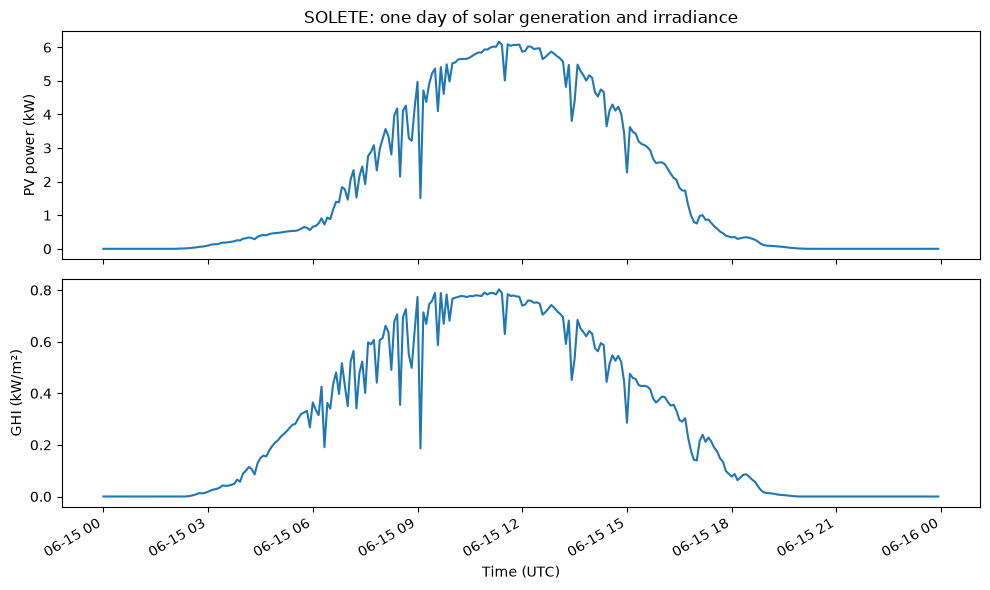

In [6]:
day = pv_data.loc["2018-06-15", ["P_Solar[kW]", "GHI[kW1m2]"]]
if day.empty:
    raise ValueError("The selected example day is missing from the SOLETE data.")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(day.index, day["P_Solar[kW]"])
axes[0].set_ylabel("PV power (kW)")
axes[0].set_title("SOLETE: one day of solar generation and irradiance")
axes[1].plot(day.index, day["GHI[kW1m2]"])
axes[1].set_ylabel("GHI (kW/m²)")
axes[1].set_xlabel("Time (UTC)")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 7. Compare the 1-minute and 5-minute measurements

We average the 1-minute observations into 5-minute intervals and compare them with the published 5-minute file. This checks whether the lower-resolution series preserves the main measurement patterns.

Numerical agreement is **not proof** of the dataset publisher's internal processing method.

In [7]:
minute_average = data["1min"].resample("5min").mean()

comparison_rows = []
for variable in ("P_Solar[kW]", "GHI[kW1m2]", "HUMIDITY[%]", "Pressure[mbar]"):
    paired = pd.concat(
        [pv_data[variable].rename("published_5min"),
         minute_average[variable].rename("average_1min")],
        axis=1, join="inner",
    ).dropna()
    difference = (paired["published_5min"] - paired["average_1min"]).abs()
    comparison_rows.append({
        "variable": variable,
        "matched_intervals": len(paired),
        "mean_abs_difference": difference.mean(),
        "max_abs_difference": difference.max(),
        "correlation": paired["published_5min"].corr(paired["average_1min"]),
    })

display(pd.DataFrame(comparison_rows).round(6))

,variable,matched_intervals,mean_abs_difference,max_abs_difference,correlation
0,P_Solar[kW],131617,0.001486,1.682116,0.999902
1,GHI[kW1m2],131617,0.000003,0.130389,0.999997
2,HUMIDITY[%],131617,0.000876,0.800000,0.988202
3,Pressure[mbar],131617,2.771678,800.000000,0.859642


## 8. Choose the modelling resolution

All our forecast horizons must be represented exactly on the source time grid. The table below shows how many data steps correspond to 15, 30 and 60 minutes.

In [8]:
step_minutes = {"60min": 60, "5min": 5, "1min": 1, "1sec": 1 / 60}
step_rows = []
for name, step in step_minutes.items():
    record = {"resolution": name}
    for horizon in (15, 30, 60):
        steps = horizon / step
        record[f"{horizon}_min_steps"] = int(steps) if steps.is_integer() else "not on grid"
    step_rows.append(record)

display(pd.DataFrame(step_rows).set_index("resolution"))

,15_min_steps,30_min_steps,60_min_steps
resolution,,,
60min,not on grid,not on grid,1
5min,3,6,12
1min,15,30,60
1sec,900,1800,3600


## Decision and next step

**We use the 5-minute SOLETE data for the main experiments.**

- It supports all three forecasting horizons (3, 6 and 12 steps).
- It retains short-term variation without the much larger computational cost of the 1-minute or 1-second data.
- We checked its time structure and measurement-quality flags above.
- The 1-minute comparison helps assess whether the 5-minute measurements preserve the main observed patterns.

This is a **practical design choice**, not a claim that 5-minute sampling always gives the most accurate forecasts.

The next notebook, **`02_data_preparation.ipynb`**, will explain each cleaning rule, prepare issue-time observational history, and ensure that no future measured weather enters a forecast.